# Exercise 3: Online Purchase Prediction Using Logistic Regression

**Subject:** Machine Learning Lab  
**Topic:** Logistic Regression

## Aim
To implement Logistic Regression to predict whether a customer will make an online purchase based on browsing activity and customer-related features.

Online Purchase Dataset:


,Pages_Visited,Time_Minutes,Products_Viewed,Purchase
0,2,5,1,0
1,5,15,4,1
2,1,3,1,0
3,8,25,7,1
4,6,20,5,1
5,3,8,2,0
6,9,30,9,1
7,4,12,3,0
8,7,22,6,1
9,2,6,1,0


Training samples: 15
Testing samples: 5
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

 No Purchase       1.00      1.00      1.00         2
    Purchase       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5

Confusion Matrix:
[[2 0]
 [0 3]]


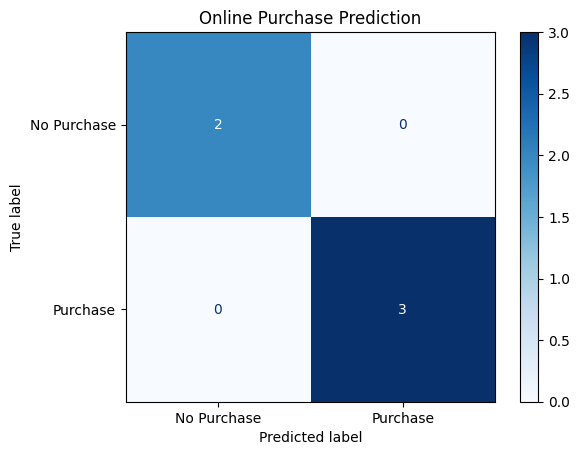


Example Prediction
Predicted result: Purchase
Estimated purchase probability: 78.23 %


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Illustrative online purchase dataset
data = {
    "Pages_Visited": [2, 5, 1, 8, 6, 3, 9, 4, 7, 2,
                      10, 5, 3, 8, 1, 6, 9, 4, 7, 2],
    "Time_Minutes": [5, 15, 3, 25, 20, 8, 30, 12, 22, 6,
                     35, 16, 9, 28, 4, 18, 32, 11, 24, 7],
    "Products_Viewed": [1, 4, 1, 7, 5, 2, 9, 3, 6, 1,
                        10, 4, 2, 8, 1, 5, 9, 3, 7, 2],
    "Purchase": [0, 1, 0, 1, 1, 0, 1, 0, 1, 0,
                 1, 1, 0, 1, 0, 1, 1, 0, 1, 0]
}

df = pd.DataFrame(data)

print("Online Purchase Dataset:")
display(df)

X = df[["Pages_Visited", "Time_Minutes", "Products_Viewed"]]
y = df["Purchase"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
).plot(cmap="Blues")

plt.title("Online Purchase Prediction")
plt.show()

# Example prediction
sample = pd.DataFrame({
    "Pages_Visited": [6],
    "Time_Minutes": [20],
    "Products_Viewed": [5]
})

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0, 1]

print("\nExample Prediction")
print("Predicted result:", "Purchase" if prediction == 1 else "No Purchase")
print("Estimated purchase probability:", round(probability * 100, 2), "%")

## Result

The Logistic Regression model was successfully implemented to predict online purchase behavior using the number of pages visited, time spent on the website, and number of products viewed.

- **Total samples:** 20
- **Training samples:** 15
- **Testing samples:** 5
- **Test accuracy:** 100%
- **Confusion matrix:** [[2, 0], [0, 3]]
- **Example prediction:** Purchase
- **Estimated purchase probability:** 78.23%

A classification report and confusion matrix were used to evaluate and visualize the model's performance.

## Conclusion

The experiment demonstrated how Logistic Regression can predict a binary outcome such as whether a customer makes an online purchase. The model classified all five test samples correctly in this illustrative dataset. A larger real-world dataset is needed to assess its generalization performance.